# Lógica difusa Mamdani con NASA POWER

## Procedencia y correspondencia con el examen
Se usa T2M diario de **NASA POWER** para coordenadas cercanas a UNMSM. La observación y conjuntos de entrada sustituyen valores sintéticos; se conservan reglas, mínimo, máximo y centroide.

In [1]:
from pathlib import Path
import json, sys, tempfile
import pandas as pd
from IPython.display import display, Image
ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
from fuzzy_logic import PowerDataset, MembershipFunction, FuzzyVariable, MamdaniRule, MamdaniController, InferenceTrace, run_exercise

## Teoría y fases
Los puntos empíricos construyen bajo, medio y alto. Se fusifica la temperatura, se evalúan reglas, se recortan consecuentes por mínimo, se agregan por máximo y se obtiene una salida nítida mediante el centroide.

,fase,operación
0,Preparación de temperatura,Validar T2M 2024 y excluir el centinela -999.
1,Construcción de membresías,Construir hombros trapezoidales bajo/alto y tr...
2,Fusificación,"Evaluar μ_baja, μ_media y μ_alta en la observa..."
3,Evaluación de reglas,"Activar bajo→lento, medio→moderado y alto→rápido."
4,Implicación por mínimo,Recortar cada conjunto consecuente con min(act...
5,Agregación por máximo,Combinar los consecuentes punto a punto median...
6,Desdifusificación por centroide,Calcular Σ(y·μ_agregada(y))/Σμ_agregada(y) sob...
7,Interpretación,Interpretar el centroide como comando porcentu...


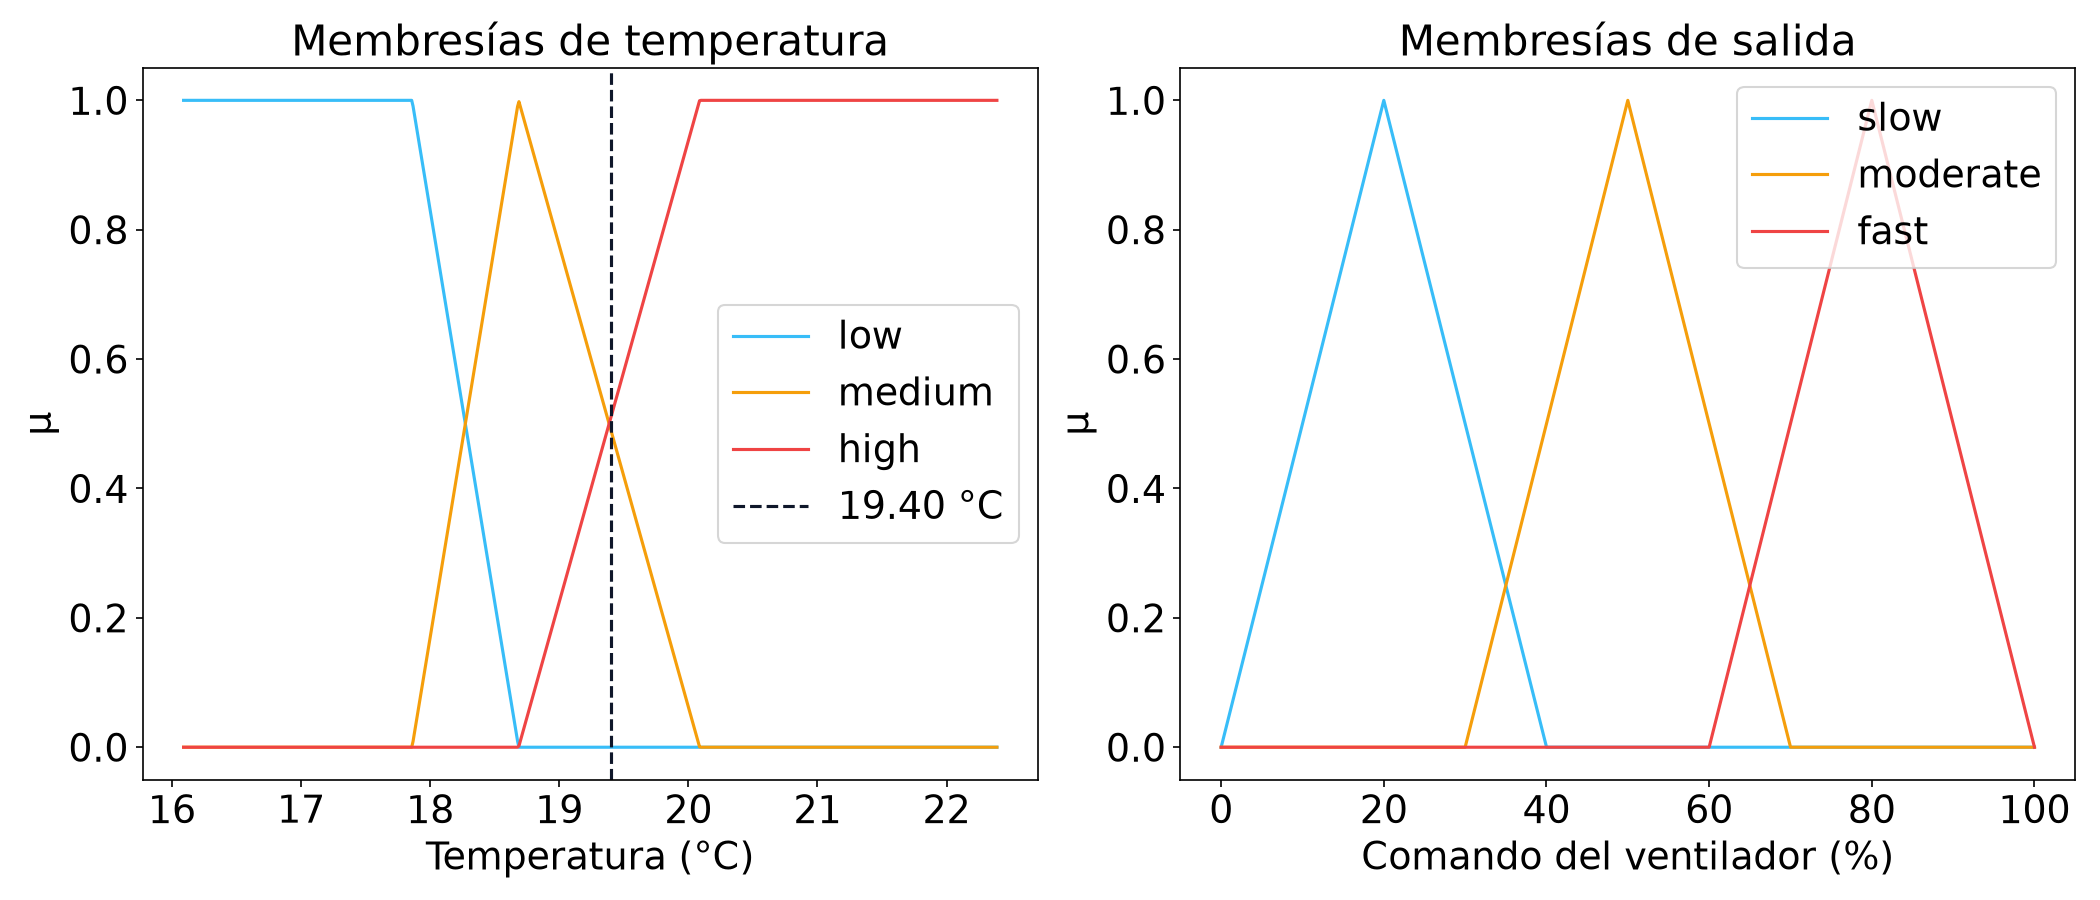

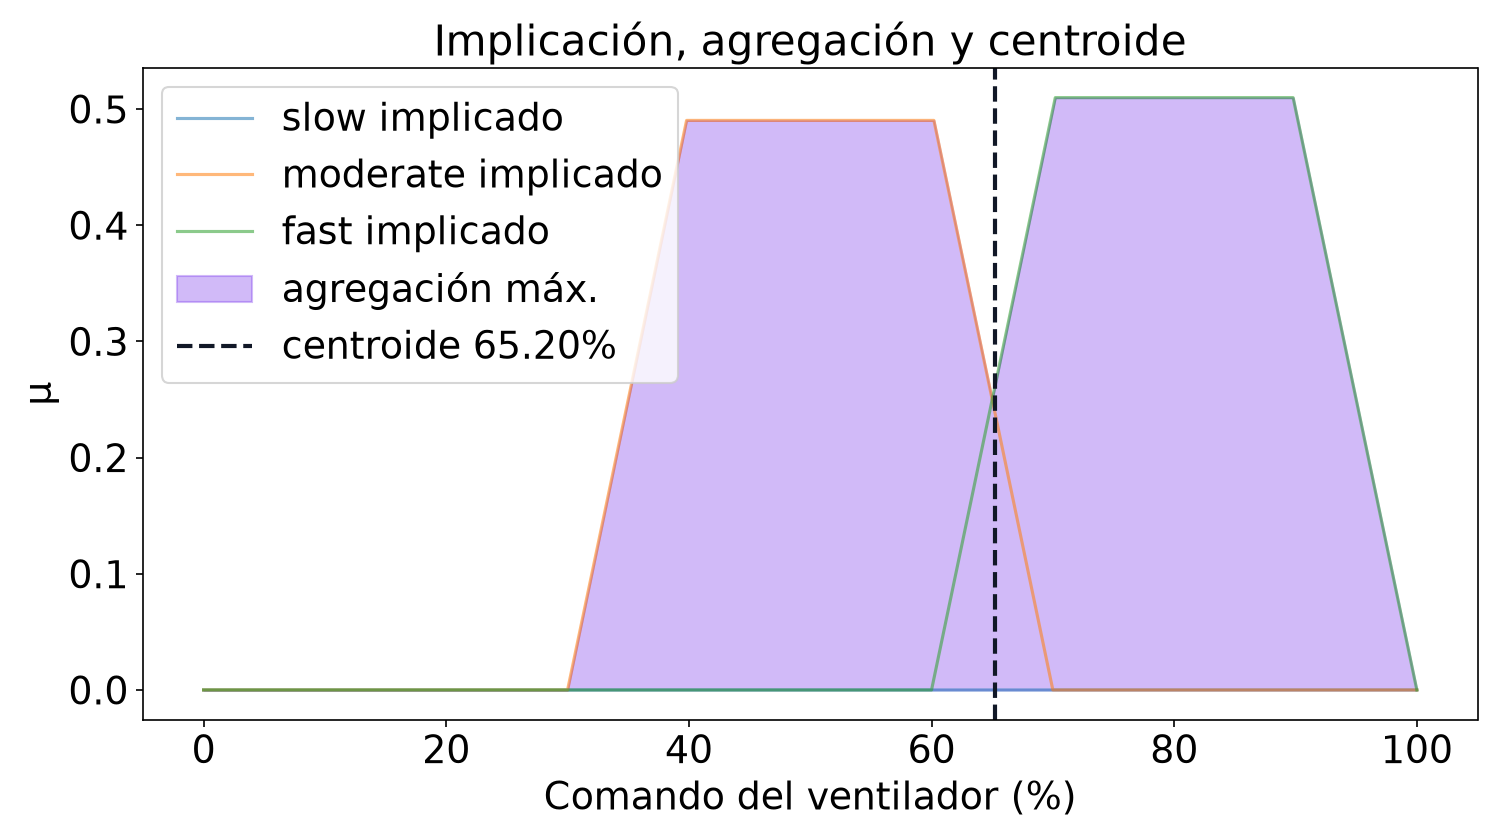

In [2]:
temporary = tempfile.TemporaryDirectory()
manifest = run_exercise(ROOT / "data/raw/nasa_power_lima_2024.json", ROOT / "data/metadata/fuzzy.json", ROOT / "configs/fuzzy.json", Path(temporary.name))
display(pd.DataFrame([{"fase": stage["title_es"], "operación": stage["operation"]} for stage in manifest["stages"]]))
display(Image(filename=str(Path(temporary.name) / "memberships.png")))
display(Image(filename=str(Path(temporary.name) / "aggregation.png")))

## Responsabilidades OOP
`PowerDataset` valida la serie; `MembershipFunction` evalúa triángulos y trapecios; `FuzzyVariable` agrupa etiquetas; `MamdaniRule` expresa reglas; `MamdaniController` ejecuta inferencia; `InferenceTrace` registra resultados.

In [3]:
display(pd.DataFrame(manifest["stages"][2]["outputs"]["memberships"].items(), columns=["conjunto", "membresía"]))
display(pd.DataFrame(manifest["pdf_mapping"]))
print(manifest["summary"]["conclusion_es"])

,conjunto,membresía
0,low,0.000000
1,medium,0.490196
2,high,0.509804


,pdf_element,original_value,treatment,replacement,justification
0,temperatura_entrada,28 °C,replaced,19.40 °C el 2024-05-14,Se usa una observación real de NASA POWER.
1,universo_temperatura,0–40 °C,replaced,16.09–22.39 °C,Se adopta el rango empírico anual de la ubicac...
2,membresias_temperatura,conjuntos fijos del enunciado,replaced,"trapecios/triángulo derivados de mínimo, cuart...",Los puntos provienen de la distribución real.
3,salida_y_reglas,lento/moderado/rápido en 0–100,retained,mismos conjuntos y tres reglas,Conserva el procedimiento Mamdani solicitado.
4,operadores,"mínimo, máximo y centroide",retained,"mínimo, máximo y centroide numérico",Son las etapas teóricas evaluadas.


Para 19.40 °C, el centroide Mamdani ordena 65.204631% de ventilación.


## Conclusión y limitaciones
El centroide produce una orden de ventilación media-alta. T2M es una media exterior modelada, no un sensor de aula, y la salida es una política diseñada, no una medición de NASA.

In [4]:
canonical = json.loads((ROOT / "results/fuzzy/result.json").read_text(encoding="utf-8"))
assert manifest == canonical
print("Paridad verificada: notebook = manifiesto difuso canónico")

Paridad verificada: notebook = manifiesto difuso canónico
